# Background

- **Author**: RUEI-HSIANG, CHANG／張睿庠（B12303030；AI協助）
- **Created At**: 2026-11-08
- **Research Motivation and Context (why are we interested in the findings?)：**
  學生明確要求在資格爭議下先把游智彬加入現行G5／G6三池，並於報告揭露。研究問題是「加入這1人後，背景組合及原候選人群別是否改變？」
  沿用兩市合併／首長／議員三池及原演算法、K診斷與seed，不加入其他分群特徵。
  精確輸入為 `data/processed/taipei_kaohsiung_yu_provisional_all_20261108.csv`、`data/processed/taipei_kaohsiung_yu_provisional_mayor_20261108.csv`、`data/processed/taipei_kaohsiung_yu_provisional_council_20261108.csv`，下方固定SHA。
  [暫納入資料文件](../data/processed/taipei_kaohsiung_yu_provisional_20261108_documentation.ipynb)、[實際處理](../data/code/include_you_zhibin_provisional_20261108.ipynb)。
  [原209人已執行版](taipei_kaohsiung_g5_g6_clustering_20261108.ipynb)作排除游智彬的對照，原檔及CSV不覆寫。
- **Main Findings and Takeaways：**
  準備後樣本合併210、首長11、議員199；兩欄缺值排除0。游智彬G5=0、G6=0，沿用既定範圍碼，分至P00。
  實際敏感度檢查：原209位候選人主群碼全不變，合併最大比例差約0.2301百分點、議員約0.2436百分點，首長0；K=2／3在固定鍵排序基準下的共同人員分割也一致（ARI=1）。原其他209位背景資料不變。
  分群是兩個二元欄位的觀察組合；silhouette=1屬重複組合的機械結果。首長小群僅作描述。
- **Future Direction：**
  游智彬列為「資格爭議／待後續確認；研究暫納入」；取得後續正式名單或資格／司法更新時再核納入決定。
  官方10/16資格不符、11/6暫時救濟抗告駁回之紀錄不改寫為已合格或官方審查未完成。
  學生認為影響可能有限，於本輪檢查分群敏感度；尚未分析投票或競選策略，不能宣稱不影響真實選舉結果。

In [1]:
from pathlib import Path
import hashlib, json, sys, platform
import numpy as np
import pandas as pd
import scipy, sklearn, matplotlib
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, fcluster, cut_tree
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 65)
VERSIONS = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                scipy=scipy.__version__, sklearn=sklearn.__version__, matplotlib=matplotlib.__version__)
print(VERSIONS)

{'python': '3.14.6', 'numpy': '2.4.6', 'pandas': '3.0.3', 'scipy': '1.18.0', 'sklearn': '1.9.0', 'matplotlib': '3.11.0'}


In [2]:
# Locate this project portably; never select data by glob order or mtime.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'AGENTS.md').is_file() and (p/'templates').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run from within the data-science-course project.')
INPUTS = {'all': {'path': 'data/processed/taipei_kaohsiung_yu_provisional_all_20261108.csv', 'sha256': '35e3b85e407d4eb91e5c96043d06a407d21e070a5920032b26f74e916f883cbe', 'rows': 210}, 'mayor': {'path': 'data/processed/taipei_kaohsiung_yu_provisional_mayor_20261108.csv', 'sha256': 'd8c448a6be69af7e6a291a376d0de31157c0267f7f41809a2a722599d3cbad65', 'rows': 11}, 'council': {'path': 'data/processed/taipei_kaohsiung_yu_provisional_council_20261108.csv', 'sha256': 'a182db22545ca308286970e49c954d3a903af3afc7d6cd4a735c53d7cd8c41bf', 'rows': 199}}
FEATURES=['G5_first_time_any_elected_office','G6_political_family']
KEY='candidate_key'
POOL_LABELS={'all':'兩市合併','mayor':'兩市首長','council':'兩市議員'}
EN_POOL={'all':'Combined','mayor':'Mayors','council':'Councillors'}
PROFILE_LABELS={'P00':'曾參選／搜尋未發現公職親屬','P01':'曾參選／有公職親屬',
                'P10':'首次參選／搜尋未發現公職親屬','P11':'首次參選／有公職親屬'}
PROFILES=list(PROFILE_LABELS)
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
inputs={}
for pool, spec in INPUTS.items():
    path=ROOT/spec['path']
    assert path.is_file(), f'Missing exact input: {path}'
    assert sha(path)==spec['sha256'], f'Input changed: {path}'
    d=pd.read_csv(path,dtype=str,keep_default_na=False)
    assert len(d)==spec['rows'] and len(d.columns)==51
    assert {KEY,'candidate_name','county_city','office_type',*FEATURES}.issubset(d.columns)
    assert d[KEY].ne('').all() and d[KEY].is_unique
    assert set(d.county_city)=={'臺北市','高雄市'}
    inputs[pool]=d
assert set(inputs['mayor'].office_type)=={'直轄市長'}
assert set(inputs['council'].office_type)=={'直轄市議員'}
a=set(inputs['all'][KEY]); m=set(inputs['mayor'][KEY]); c=set(inputs['council'][KEY])
assert m.isdisjoint(c) and m|c==a
for pool in ['mayor','council']:
    pd.testing.assert_frame_equal(inputs[pool].set_index(KEY).sort_index(),
        inputs['all'].set_index(KEY).loc[inputs[pool][KEY]].sort_index())
print('逐檔SHA、51欄schema、逐人鍵及三池分割通過。')
display(Markdown('**表1：合併池前10筆（原始N=210）；僅呈現識別與本次使用欄位。**'))
display(inputs['all'][[KEY,'candidate_name','county_city','office_type',*FEATURES]].head(10).rename(columns={KEY:'候選人鍵','candidate_name':'姓名','county_city':'縣市','office_type':'公職',FEATURES[0]:'首次參選G5',FEATURES[1]:'公職親屬G6'}))

逐檔SHA、51欄schema、逐人鍵及三池分割通過。


**表1：合併池前10筆（原始N=210）；僅呈現識別與本次使用欄位。**

,候選人鍵,姓名,縣市,公職,首次參選G5,公職親屬G6
0,2026-C1-001,郭璽,臺北市,直轄市長,0,0
1,2026-C1-002,沈伯洋,臺北市,直轄市長,0,1
2,2026-C1-003,蕭文乾,臺北市,直轄市長,0,0
3,2026-C1-004,唐新民,臺北市,直轄市長,0,0
4,2026-C1-005,蔣萬安,臺北市,直轄市長,0,1
5,2026-C1-006,林志成,臺北市,直轄市長,0,0
6,2026-C1-019,張靜,高雄市,直轄市長,0,0
7,2026-C1-020,賴瑞隆,高雄市,直轄市長,0,0
8,2026-C1-021,王肇民,高雄市,直轄市長,1,0
9,2026-C1-022,柯志恩,高雄市,直轄市長,0,1


### 變數定義與樣本規則

G5=1：依楊喬茵修訂規則編為首次參選**任何民選公職**；G5=0：有可核對的先前參選紀錄，未當選也算。
G6=1：依既有範圍有符合資格的公職親屬；G6=0：完成紀錄中的網路搜尋未發現符合親屬，不是證明沒有。
配偶與三親等內血／姻親沿用上游範圍，一般軍職及常任文官依學生指示排除；證據來源與推論註記隨逐人輸出保留。

空字串或明確缺值標記才算缺值，0是有效類別。未知列不填0；非空但不屬於0／1的值立即停止。
只檢查 G5／G6；其他欄位缺失不排除。本次依學生明確決定暫納入游智彬；研究暫納入旗標與官方資格紀錄分開。其G6補查全文指出外叔公游日正為四親等，超出三親等，外公一般軍文職也依既定規則排除。G6=0表示搜尋未發現符合範圍者，不能解讀為沒有任何政治人物親戚。
county_city、office_type只用來確認樣本及呈現組成，不納入距離。三池各自擬合。

In [3]:
MISSING={'','na','n/a','nan','none','null','unknown','未知','待核','待確認'}
prepared={}; exclusions=[]; sample_rows=[]
for pool,d in inputs.items():
    x=d[FEATURES].apply(lambda s:s.str.strip())
    missing=x.apply(lambda s:s.str.lower().isin(MISSING))
    bad=(~missing)&(~x.isin(['0','1']))
    assert not bad.any().any(), f'Unexpected nonbinary values in {pool}'
    keep=~missing.any(axis=1)
    for idx in d.index[~keep]:
        exclusions.append({'pool':pool,KEY:d.at[idx,KEY],'candidate_name':d.at[idx,'candidate_name'],
            'missing_fields':';'.join(f for f in FEATURES if missing.at[idx,f]),
            'reason':'missing_G5_or_G6'})
    q=d.loc[keep].copy();q[FEATURES]=x.loc[keep]
    q=q.sort_values(KEY,kind='stable').reset_index(drop=True)
    prepared[pool]=q
    sample_rows.append({'pool':pool,'input_n':len(d),'included_n':len(q),'excluded_n':int((~keep).sum()),
                        'G5_missing_n':int(missing[FEATURES[0]].sum()),'G6_missing_n':int(missing[FEATURES[1]].sum())})
sample=pd.DataFrame(sample_rows)
exclusion_df=pd.DataFrame(exclusions,columns=['pool',KEY,'candidate_name','missing_fields','reason'])
display(Markdown('**表2：G5／G6完整觀察篩選（各池原始N見input_n）；三池非互斥。**'))
display(sample.rename(columns={'pool':'樣本池','input_n':'原始人數','included_n':'保留人數','excluded_n':'缺值排除人數','G5_missing_n':'G5缺值人數','G6_missing_n':'G6缺值人數'}))
assert len(exclusion_df)==0
assert prepared['all'].G1_age_2026_minus_birth_year.eq('').sum()==21
print('21位年齡缺值者仍保留；本次只使用G5、G6。')

**表2：G5／G6完整觀察篩選（各池原始N見input_n）；三池非互斥。**

,樣本池,原始人數,保留人數,缺值排除人數,G5缺值人數,G6缺值人數
0,all,210,210,0,0,0
1,mayor,11,11,0,0,0
2,council,199,199,0,0,0


21位年齡缺值者仍保留；本次只使用G5、G6。


### 使用變數的摘要統計

G5、G6為二元類別，不因儲存為數字就當成連續變數。以下每池列出所有類別的次數與非缺值分母百分比，並另列缺值數。
縣市與公職只作樣本核對，不作地理分群或特徵。candidate_key及姓名只作識別；來源欄只是原樣保留的稽核資訊。
資格暫納入旗標只用作樣本與敏感度核對，不進距離，以下亦列其人數分布。

In [4]:
VARIABLE_LABELS={FEATURES[0]:'G5 首次參選任何民選公職',FEATURES[1]:'G6 公職親屬搜尋編碼',
                 'county_city':'縣市（不入分群）','office_type':'公職（不入分群）','eligibility_provisional_flag_20261108':'資格爭議暫納入旗標（不入分群）'}
VALUE_LABELS={FEATURES[0]:{'0':'曾參選','1':'首次參選'},
              FEATURES[1]:{'0':'搜尋未發現公職親屬','1':'有公職親屬'}, 'eligibility_provisional_flag_20261108':{'0':'原209人版保留','1':'資格爭議研究暫納入'}}
summary=[]
for pool,d in prepared.items():
    for f,label in VARIABLE_LABELS.items():
        counts=d[f].value_counts(dropna=False)
        for value,n in counts.items():
            summary.append({'樣本池':POOL_LABELS[pool],'變數':label,
                '類別':VALUE_LABELS.get(f,{}).get(value,value),'有效N':len(d),'缺值N':0,
                '人數':int(n),'百分比':round(100*n/len(d),2)})
display(Markdown('**表3：每個使用類別變數之分布（合併N=210、首長N=11、議員N=199；百分比以各池有效N為分母）。**'))
display(pd.DataFrame(summary))

**表3：每個使用類別變數之分布（合併N=210、首長N=11、議員N=199；百分比以各池有效N為分母）。**

,樣本池,變數,類別,有效N,缺值N,人數,百分比
0,兩市合併,G5 首次參選任何民選公職,曾參選,210,0,160,76.19
1,兩市合併,G5 首次參選任何民選公職,首次參選,210,0,50,23.81
2,兩市合併,G6 公職親屬搜尋編碼,搜尋未發現公職親屬,210,0,144,68.57
3,兩市合併,G6 公職親屬搜尋編碼,有公職親屬,210,0,66,31.43
4,兩市合併,縣市（不入分群）,高雄市,210,0,106,50.48
5,兩市合併,縣市（不入分群）,臺北市,210,0,104,49.52
6,兩市合併,公職（不入分群）,直轄市議員,210,0,199,94.76
7,兩市合併,公職（不入分群）,直轄市長,210,0,11,5.24
8,兩市合併,資格爭議暫納入旗標（不入分群）,原209人版保留,210,0,209,99.52
9,兩市合併,資格爭議暫納入旗標（不入分群）,資格爭議研究暫納入,210,0,1,0.48


### The actual analysis starts below

#### 距離、演算法與群數

沿用[既有提案](../report/DSSI2026-group-3.md)的對稱 Gower 類別距離及 average linkage。
本次只有兩個等權重二元欄位，距離恰等於 Hamming distance：

\[
d(i,j)=\{\mathbf{1}[G5_i\ne G5_j]+\mathbf{1}[G6_i\ne G6_j]\}/2\in\{0,0.5,1\}.
\]

G6的0也算一次有效搜尋編碼，故兩個0的相同結果會增加相似度；這是分析設定，並非親屬不存在的斷言。
先以候選人鍵排序，再將凝聚式階層樹切在距離0，保留不同已觀察組合；群數最多4，不拆開完全相同資料製造第5群。
群別以固定 P00／P01／P10／P11 表示 G5、G6 順序，方便跨池核對，沒有高低或優劣順序。

另比較 K=2到該池非空組合數（至多4）。較少群會合併不同組合；0.5距離可能並列，補做100次列順序重排。
主結果採零距離群，不把對K=4機械性最高的silhouette當成獨立選群證據。
以原提案每群約8–10人的下界8作人數診斷；首長只有11人，任何K≥2都不可能每群至少8人，故保留其描述性結果與不通過標記。

技術參考：[SciPy average linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html)、
[scikit-learn silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)。實際套件版本見最前方輸出，未假稱與網站版本相同。

In [5]:
def canonical(labels, frame):
    # Stable local C labels for alternative K; identical IDs are not compared across K or pools.
    groups={int(label):tuple(sorted(set('P'+r[0]+r[1] for r in
             frame.loc[np.asarray(labels)==label,FEATURES].itertuples(index=False,name=None))))
            for label in np.unique(labels)}
    mapping={old:i+1 for i,old in enumerate(sorted(groups,key=lambda t:groups[t]))}
    return np.array([mapping[int(t)] for t in labels])

fits={}; assignments={}; metrics=[]; alternatives=[]; profile_rows=[]
for pool,d in prepared.items():
    X=d[FEATURES].to_numpy(dtype=int)
    distances=pdist(X,metric='hamming')
    D=squareform(distances)
    assert set(np.unique(D)).issubset({0.0,0.5,1.0})
    # Pass a condensed distance vector; do not reinterpret the square matrix as observations.
    Z=linkage(distances,method='average',optimal_ordering=False)
    primary=fcluster(Z,t=0.0,criterion='distance')
    profile='P'+d[FEATURES[0]]+d[FEATURES[1]]
    primary_k=len(np.unique(primary))
    assert primary_k==profile.nunique()
    match=pd.DataFrame({'label':primary,'profile':profile})
    assert match.groupby('label').profile.nunique().eq(1).all()
    assert match.groupby('profile').label.nunique().eq(1).all()
    sil=silhouette_samples(D,primary,metric='precomputed')
    metadata=[KEY,'candidate_name','county_city','office_type','electoral_district',*FEATURES,
              'G5_label','G6_label','G5_audit_status','G5_source','G6_evidence_tier','G6_source','G6_review_note_tk_20261108','eligibility_status_20261108','eligibility_source_20261108','research_inclusion_status_20261108','official_eligibility_note_20261108','eligibility_provisional_flag_20261108','provisional_inclusion_source_20261108']
    out=d[metadata].copy()
    out['clustering_pool']=pool
    out['cluster_profile_id']=profile
    out['cluster_profile_label']=profile.map(PROFILE_LABELS)
    out['primary_k']=primary_k
    out['primary_silhouette']=sil
    assignments[pool]=out
    fits[pool]={'X':X,'D':D,'Z':Z,'primary':primary,'profile':profile,'k':primary_k,'alternatives':{}}
    for pid,label in PROFILE_LABELS.items():
        n=int(profile.eq(pid).sum())
        profile_rows.append({'pool':pool,'profile_id':pid,'profile_label':label,'G5':int(pid[1]),'G6':int(pid[2]),
            'n':n,'pool_n':len(d),'percent':100*n/len(d),'observed':n>0})
    for k in range(2,primary_k+1):
        labels=canonical(cut_tree(Z,n_clusters=k).ravel(),d)
        fits[pool]['alternatives'][k]=labels
        counts=pd.Series(labels).value_counts().sort_index()
        patterns=['+'.join(sorted(profile[labels==label].unique())) for label in counts.index]
        metrics.append({'pool':pool,'pool_n':len(d),'requested_k':k,'actual_k':len(counts),
            'silhouette_mean':float(silhouette_score(D,labels,metric='precomputed')),
            'min_cluster_n':int(counts.min()),'max_cluster_n':int(counts.max()),
            'all_clusters_n_ge_8':bool(counts.min()>=8),'is_primary':k==primary_k,
            'cluster_sizes':'|'.join(map(str,counts.tolist())),
            'cluster_profiles':'|'.join(patterns)})
        for i,row in d.iterrows():
            alternatives.append({'pool':pool,KEY:row[KEY],'k':k,'cluster_id':f'C{labels[i]}',
                                 'cluster_profiles':patterns[int(labels[i])-1]})
profiles=pd.DataFrame(profile_rows)
diagnostics=pd.DataFrame(metrics)
alternative_assignments=pd.DataFrame(alternatives)
display(Markdown('**表4：零距離主分群人數（合併N=210、首長N=11、議員N=199）；0人組合不計入非空群數。**'))
display(profiles.pivot(index=['profile_id','profile_label'],columns='pool',values='n')[['all','mayor','council']]
        .rename(columns=POOL_LABELS))
display(Markdown('**表5：K=2–4診斷（N依pool_n；min_cluster_n為最小群人數，主結果為is_primary）。**'))
display(diagnostics.round({'silhouette_mean':4}).rename(columns={'pool':'樣本池','pool_n':'樣本人數','requested_k':'要求群數','actual_k':'實際群數','silhouette_mean':'平均silhouette','min_cluster_n':'最小群人數','max_cluster_n':'最大群人數','all_clusters_n_ge_8':'每群至少8人','is_primary':'主結果','cluster_sizes':'各群人數','cluster_profiles':'各群組合'}))

**表4：零距離主分群人數（合併N=210、首長N=11、議員N=199）；0人組合不計入非空群數。**

,pool,兩市合併,兩市首長,兩市議員
profile_id,profile_label,,,
P00,曾參選／搜尋未發現公職親屬,109,6,103
P01,曾參選／有公職親屬,51,3,48
P10,首次參選／搜尋未發現公職親屬,35,2,33
P11,首次參選／有公職親屬,15,0,15


**表5：K=2–4診斷（N依pool_n；min_cluster_n為最小群人數，主結果為is_primary）。**

,樣本池,樣本人數,要求群數,實際群數,平均silhouette,最小群人數,最大群人數,每群至少8人,主結果,各群人數,各群組合
0,all,210,2,2,0.7050,50,160,True,False,160|50,P00+P01|P10+P11
1,all,210,3,3,0.8980,50,109,True,False,109|51|50,P00|P01|P10+P11
2,all,210,4,4,1.0000,15,109,True,True,109|51|35|15,P00|P01|P10|P11
3,mayor,11,2,2,0.6932,2,9,False,False,9|2,P00+P01|P10
4,mayor,11,3,3,1.0000,2,6,False,True,6|3|2,P00|P01|P10
5,council,199,2,2,0.7040,48,151,True,False,151|48,P00+P01|P10+P11
6,council,199,3,3,0.8942,48,103,True,False,103|48|48,P00|P01|P10+P11
7,council,199,4,4,1.0000,15,103,True,True,103|48|33|15,P00|P01|P10|P11


合併及議員的四群就是四個 G5／G6 組合，首長缺 P11（首次參選且有公職親屬）組合。
每位候選人的同群距離皆0、到其他群距離為正，因此主分群silhouette=1；同一組合有多人的重複資料即可造成這個結果，不能解讀為「完美發現政治類型」。
主結果不以分群標籤預測G5／G6，也不把這兩欄的群間差異當成新的統計發現。

In [6]:
SEED=20261108
PERMUTATIONS=100
order_rows=[]
for pool,d in prepared.items():
    fit=fits[pool];rng=np.random.default_rng(SEED)
    values={k:[] for k in fit['alternatives']}
    primary_ari=[]
    for b in range(PERMUTATIONS):
        perm=rng.permutation(len(d))
        Zp=linkage(pdist(fit['X'][perm],metric='hamming'),method='average')
        lp=fcluster(Zp,t=0,criterion='distance')
        back=np.empty(len(d),dtype=int);back[perm]=lp
        primary_ari.append(adjusted_rand_score(fit['primary'],back))
        for k,base in fit['alternatives'].items():
            lp=cut_tree(Zp,n_clusters=k).ravel()
            back=np.empty(len(d),dtype=int);back[perm]=lp
            values[k].append(adjusted_rand_score(base,back))
    assert np.allclose(primary_ari,1)
    for k,scores in values.items():
        order_rows.append({'pool':pool,'k':k,'permutations':PERMUTATIONS,'seed':SEED,
            'ARI_min':min(scores),'ARI_mean':float(np.mean(scores)),
            'same_partition_fraction':float(np.mean(np.isclose(scores,1))),
            'primary_profile_cut':k==fit['k']})
order_check=pd.DataFrame(order_rows)
display(Markdown('**表6：100次列順序重排（各池N不變）；ARI=1表示相同分割，僅檢查距離並列的實作敏感度。**'))
display(order_check.round(4).rename(columns={'pool':'樣本池','k':'群數','permutations':'重排次數','seed':'亂數種子','ARI_min':'最小ARI','ARI_mean':'平均ARI','same_partition_fraction':'相同分割比例','primary_profile_cut':'主結果'}))

**表6：100次列順序重排（各池N不變）；ARI=1表示相同分割，僅檢查距離並列的實作敏感度。**

,樣本池,群數,重排次數,亂數種子,最小ARI,平均ARI,相同分割比例,主結果
0,all,2,100,20261108,-0.0084,0.5563,0.56,False
1,all,3,100,20261108,0.4732,0.8927,0.49,False
2,all,4,100,20261108,1.0000,1.0000,1.00,True
3,mayor,2,100,20261108,-0.1411,0.2925,0.38,False
4,mayor,3,100,20261108,1.0000,1.0000,1.00,True
5,council,2,100,20261108,-0.0049,0.5780,0.58,False
6,council,3,100,20261108,0.4746,0.9114,0.55,False
7,council,4,100,20261108,1.0000,1.0000,1.00,True


#### Bootstrap：小群是否會在重抽中消失

依提案補做500次候選人等機率有放回重抽，各次仍使用平均連結、距離0切群；固定seed=20261108。
重複抽中的同一候選人以集合計算Jaccard，不將複本當成新人物。
每個原群與重抽群比對最大Jaccard，分別報告：
(1) 原群完整候選人集合的平均Jaccard（未被抽中的原成員仍在分母，因此受抽樣涵蓋率影響）；
(2) 只比較當次抽到的共同支持集合、且原群有被抽到時的平均Jaccard；
(3) 原群完全沒被抽到的比例。
在本題共同支持分群一致是相同兩欄組合的必然結果，不能視為對來源編碼正確性、外部效度或潛在類型的認證。

In [7]:
BOOTSTRAPS=500
bootstrap_rows=[]
for pool,d in prepared.items():
    fit=fits[pool];rng=np.random.default_rng(SEED)
    groups={pid:set(np.flatnonzero(fit['profile'].to_numpy()==pid))
            for pid in PROFILES if (fit['profile']==pid).any()}
    records={pid:{'full':[],'common':[],'absent':0} for pid in groups}
    for b in range(BOOTSTRAPS):
        draw=rng.integers(0,len(d),size=len(d))
        boot=fit['X'][draw]
        Zb=linkage(pdist(boot,metric='hamming'),method='average')
        lab=fcluster(Zb,t=0,criterion='distance')
        boot_groups=[set(draw[lab==label].tolist()) for label in np.unique(lab)]
        support=set(draw.tolist())
        for pid,original in groups.items():
            common=original&support
            records[pid]['full'].append(max(len(original&g)/len(original|g) for g in boot_groups))
            if not common:
                records[pid]['absent']+=1
            else:
                records[pid]['common'].append(max(len(common&g)/len(common|g) for g in boot_groups))
    for pid,r in records.items():
        bootstrap_rows.append({'pool':pool,'profile_id':pid,'original_n':len(groups[pid]),
            'pool_n':len(d),'B':BOOTSTRAPS,'seed':SEED,
            'jaccard_full_universe_mean':float(np.mean(r['full'])),
            'jaccard_common_support_mean_when_present':float(np.mean(r['common'])),
            'absent_n':r['absent'],'absent_fraction':r['absent']/BOOTSTRAPS})
bootstrap=pd.DataFrame(bootstrap_rows)
display(Markdown('**表7：主分群500次bootstrap（各池N見pool_n）；完整集合Jaccard受重抽涵蓋率影響，非信賴區間。**'))
display(bootstrap.round(4).rename(columns={'pool':'樣本池','profile_id':'組合','original_n':'原群人數','pool_n':'樣本人數','B':'重抽次數','seed':'亂數種子','jaccard_full_universe_mean':'完整原群平均Jaccard','jaccard_common_support_mean_when_present':'抽到成員條件下平均Jaccard','absent_n':'整群未抽到次數','absent_fraction':'整群未抽到比例'}))

**表7：主分群500次bootstrap（各池N見pool_n）；完整集合Jaccard受重抽涵蓋率影響，非信賴區間。**

,樣本池,組合,原群人數,樣本人數,重抽次數,亂數種子,完整原群平均Jaccard,抽到成員條件下平均Jaccard,整群未抽到次數,整群未抽到比例
0,all,P00,109,210,500,20261108,0.6321,1.0,0,0.000
1,all,P01,51,210,500,20261108,0.6333,1.0,0,0.000
2,all,P10,35,210,500,20261108,0.6302,1.0,0,0.000
3,all,P11,15,210,500,20261108,0.6367,1.0,0,0.000
4,mayor,P00,6,11,500,20261108,0.6407,1.0,0,0.000
5,mayor,P01,3,11,500,20261108,0.6453,1.0,17,0.034
6,mayor,P10,2,11,500,20261108,0.6730,1.0,43,0.086
7,council,P00,103,199,500,20261108,0.6317,1.0,0,0.000
8,council,P01,48,199,500,20261108,0.6320,1.0,0,0.000
9,council,P10,33,199,500,20261108,0.6313,1.0,0,0.000


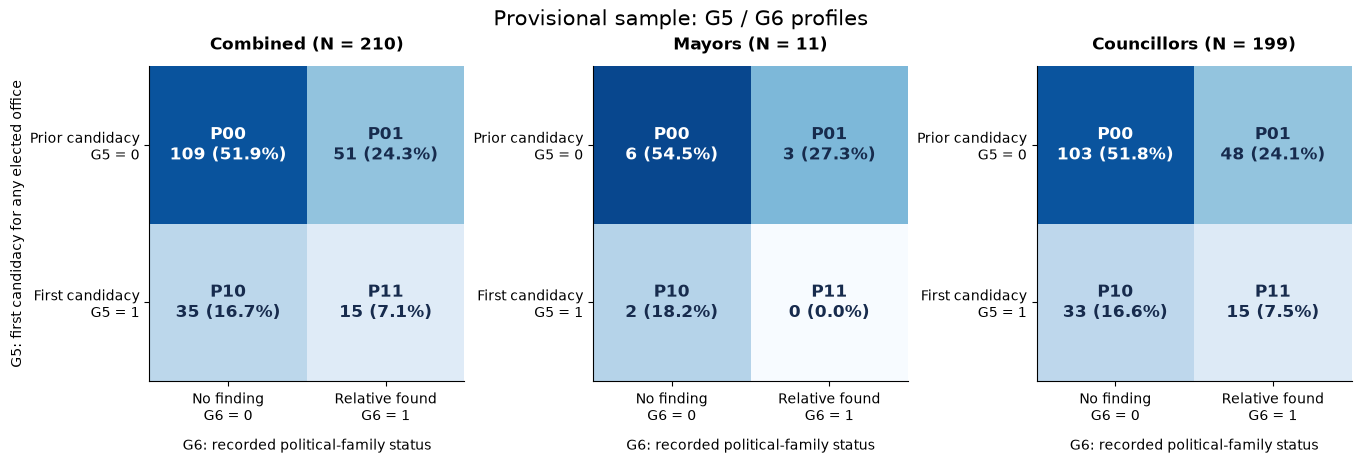

In [8]:
ASSET=ROOT/'finding/taipei_kaohsiung_g5_g6_yu_provisional_20261108_assets'
ASSET.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,axes=plt.subplots(1,3,figsize=(13.5,4.5),constrained_layout=True)
for ax,pool in zip(axes,INPUTS):
    counts=profiles[profiles.pool==pool].set_index('profile_id').n
    ns=np.array([[counts['P00'],counts['P01']],[counts['P10'],counts['P11']]])
    perc=100*ns/len(prepared[pool])
    ax.imshow(perc,vmin=0,vmax=60,cmap='Blues',aspect='equal')
    for i in range(2):
        for j in range(2):
            pid=f'P{i}{j}'
            ax.text(j,i,f'{pid}\n{ns[i,j]} ({perc[i,j]:.1f}%)',ha='center',va='center',
                    color='white' if perc[i,j]>40 else '#172b4d',fontsize=12,fontweight='bold')
    ax.set_xticks([0,1],['No finding\nG6 = 0','Relative found\nG6 = 1'])
    ax.set_yticks([0,1],['Prior candidacy\nG5 = 0','First candidacy\nG5 = 1'])
    ax.set_xlabel('G6: recorded political-family status',labelpad=10)
    ax.set_ylabel('G5: first candidacy for any elected office' if pool=='all' else '')
    ax.set_title(f'{EN_POOL[pool]} (N = {len(prepared[pool])})',fontweight='bold',pad=12)
fig.suptitle('Provisional sample: G5 / G6 profiles',fontsize=15)
fig.savefig(ASSET/'profile_counts.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

圖1顯示研究暫納入後的人數與池內比例。游智彬加入P00，合併P00為109／210（51.9%），議員P00為103／199（51.8%）；首長P00維持6／11（54.5%）。
本圖反映這份暫納入研究樣本，不代表官方已核准其候選人資格。No finding表示紀錄搜尋未發現符合定義的公職親屬。
這是觀察分布，非更大母體平均值的估計，故不加不適用的平均值信賴區間。

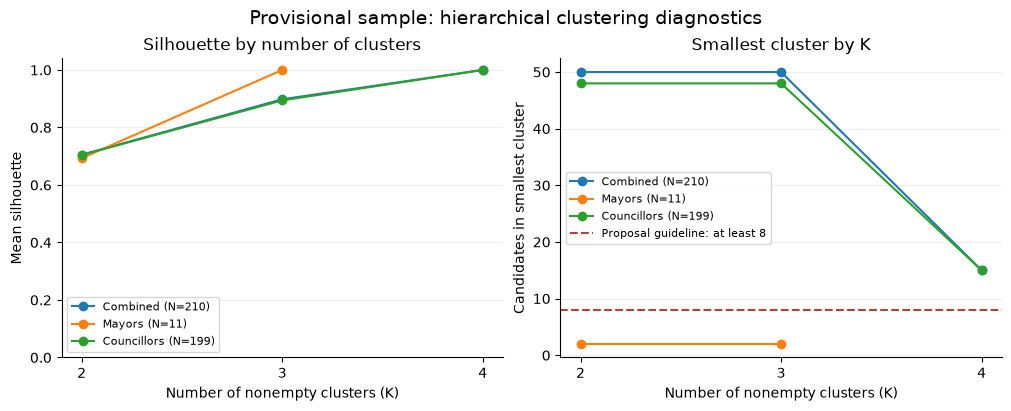

In [9]:
fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for pool,g in diagnostics.groupby('pool',sort=False):
    label=f'{EN_POOL[pool]} (N={len(prepared[pool])})'
    axes[0].plot(g.requested_k,g.silhouette_mean,marker='o',label=label)
    axes[1].plot(g.requested_k,g.min_cluster_n,marker='o',label=label)
axes[0].set(title='Silhouette by number of clusters',xlabel='Number of nonempty clusters (K)',ylabel='Mean silhouette',ylim=(0,1.04))
axes[1].set(title='Smallest cluster by K',xlabel='Number of nonempty clusters (K)',ylabel='Candidates in smallest cluster')
axes[1].axhline(8,color='#b74032',linestyle='--',label='Proposal guideline: at least 8')
for ax in axes:
    ax.set_xticks([2,3,4]);ax.legend(fontsize=8);ax.grid(axis='y',alpha=.2)
fig.suptitle('Provisional sample: hierarchical clustering diagnostics',fontsize=14)
fig.savefig(ASSET/'k_diagnostics.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

圖2比較不同K的分離度與最小群人數。最大的可用K只是保留全部不同組合；不能只看左圖silhouette=1就下實質類型結論。
首長池的群數與人數在右圖直接顯示其小樣本限制。較少K的合併結果需同時查看表6的列順序敏感度，不將其中一種並列解誤稱唯一分類。

### 納入游智彬的敏感度檢查

將新三池主群指派與保存的209人版逐人按candidate_key比對，報告共同候選人的群碼變動與ARI；另比較四組合的池內百分比差（百分點）。
替代K也用共同候選人的ARI核對，避免只看人數就宣稱沒有改變。這些檢查只衡量本次分群，沒有選票、勝負或席次資料。

In [10]:
BASELINE_PINS = {'data/processed/tk_g5_g6_all_assignments_20261108.csv': 'f54b623ccced6a8d5b8fd5cbd264379f9d4c2be6451a2f05c88ed4772ad7309b', 'data/processed/tk_g5_g6_mayor_assignments_20261108.csv': '1645b06697ea9d18c212e2712f882c8aba3ec5a83cf6d7df5ca5d57b1bcea8ee', 'data/processed/tk_g5_g6_council_assignments_20261108.csv': 'efa5c7af2d23a4565791a29612793af6863c5ceb71190529b91da34d4f93fd1a', 'data/processed/tk_g5_g6_profiles_20261108.csv': '0077eda8bd3ea98313ed9add9c88a481bee966bce2ede6efd0ca3879b97dd75a', 'data/processed/tk_g5_g6_alternative_assignments_20261108.csv': '33a2a83f62b49af55e79c77fd6dc027802f801a22ded166c222f7f1b424c6d70'}
for rel,expected in BASELINE_PINS.items():
    assert sha(ROOT/rel)==expected,rel
baseline={p:pd.read_csv(ROOT/f'data/processed/tk_g5_g6_{p}_assignments_20261108.csv',dtype=str,keep_default_na=False) for p in INPUTS}
baseline_profiles=pd.read_csv(ROOT/'data/processed/tk_g5_g6_profiles_20261108.csv')
baseline_alts=pd.read_csv(ROOT/'data/processed/tk_g5_g6_alternative_assignments_20261108.csv',dtype=str,keep_default_na=False)
profile_comparison=[];sample_comparison=[]
for pool,current in assignments.items():
    old=baseline[pool]
    common=old[[KEY,'cluster_profile_id']].merge(current[[KEY,'cluster_profile_id']],on=KEY,
            validate='one_to_one',suffixes=('_before','_after'))
    assert len(common)==len(old)
    changed=int(common.cluster_profile_id_before.ne(common.cluster_profile_id_after).sum())
    ari=float(adjusted_rand_score(common.cluster_profile_id_before,common.cluster_profile_id_after))
    for pid in PROFILES:
        before=baseline_profiles[(baseline_profiles.pool==pool)&(baseline_profiles.profile_id==pid)].iloc[0]
        after=profiles[(profiles.pool==pool)&(profiles.profile_id==pid)].iloc[0]
        profile_comparison.append({'pool':pool,'profile_id':pid,'before_n':int(before.n),'after_n':int(after.n),
            'before_pool_n':len(old),'after_pool_n':len(current),'before_percent':100*int(before.n)/len(old),
            'after_percent':100*int(after.n)/len(current),'percent_change_pp':100*int(after.n)/len(current)-100*int(before.n)/len(old)})
    # Alternative C labels are local: compare partitions through ARI, not label equality.
    alternative_ari={}
    for k in [2,3]:
        old_k=baseline_alts[(baseline_alts.pool==pool)&baseline_alts.k.eq(str(k))]
        new_k=alternative_assignments[(alternative_assignments.pool==pool)&alternative_assignments.k.eq(k)]
        paired=old_k[[KEY,'cluster_id']].merge(new_k[[KEY,'cluster_id']],on=KEY,validate='one_to_one',suffixes=('_before','_after'))
        assert len(paired)==len(old)
        alternative_ari[f'k{k}_common_ARI']=float(adjusted_rand_score(paired.cluster_id_before,paired.cluster_id_after))
    delta=max(abs(r['percent_change_pp']) for r in profile_comparison if r['pool']==pool)
    sample_comparison.append({'pool':pool,'before_n':len(old),'after_n':len(current),'common_n':len(common),
        'primary_changed_n':changed,'primary_common_ARI':ari,
        'before_k':int(old.primary_k.iloc[0]),'after_k':fits[pool]['k'],
        'max_absolute_percent_change_pp':delta,'new_provisional_n':int(current.eligibility_provisional_flag_20261108.eq('1').sum()),
        **alternative_ari})
sensitivity=pd.DataFrame(sample_comparison)
profile_sensitivity=pd.DataFrame(profile_comparison)
assert sensitivity.primary_changed_n.eq(0).all() and sensitivity.primary_common_ARI.eq(1).all()
yu_key='2026|直轄市議員|臺北市第6選舉區|游智彬'
assert assignments['all'].set_index(KEY).at[yu_key,'cluster_profile_id']=='P00'
assert assignments['council'].set_index(KEY).at[yu_key,'cluster_profile_id']=='P00'
assert yu_key not in set(assignments['mayor'][KEY])
display(Markdown('**表8：納入／排除敏感度（各池N見表；共同人員僅計各池一次，三池非互斥）。**'))
display(sensitivity.rename(columns={'pool':'樣本池','before_n':'納入前N','after_n':'納入後N','common_n':'共同人數','primary_changed_n':'主群變動人數','primary_common_ARI':'主群共同人員ARI','before_k':'原群數','after_k':'新群數','max_absolute_percent_change_pp':'最大比例變動（百分點）','new_provisional_n':'資格爭議暫納入人數','k2_common_ARI':'K2共同人員ARI','k3_common_ARI':'K3共同人員ARI'}))
display(Markdown('**表9：各組合人數與池內百分比變化；分母各為納入前／後池人數。**'))
display(profile_sensitivity.round(4).rename(columns={'pool':'樣本池','profile_id':'組合碼','before_n':'原人數','after_n':'新人數','before_pool_n':'原池N','after_pool_n':'新池N','before_percent':'原百分比','after_percent':'新百分比','percent_change_pp':'差異（百分點）'}))

**表8：納入／排除敏感度（各池N見表；共同人員僅計各池一次，三池非互斥）。**

,樣本池,納入前N,納入後N,共同人數,主群變動人數,主群共同人員ARI,原群數,新群數,最大比例變動（百分點）,資格爭議暫納入人數,K2共同人員ARI,K3共同人員ARI
0,all,209,210,209,0,1.0,4,4,0.230121,1,1.0,1.0
1,mayor,11,11,11,0,1.0,3,3,0.000000,0,1.0,1.0
2,council,198,199,198,0,1.0,4,4,0.243642,1,1.0,1.0


**表9：各組合人數與池內百分比變化；分母各為納入前／後池人數。**

,樣本池,組合碼,原人數,新人數,原池N,新池N,原百分比,新百分比,差異（百分點）
0,all,P00,108,109,209,210,51.6746,51.9048,0.2301
1,all,P01,51,51,209,210,24.4019,24.2857,-0.1162
2,all,P10,35,35,209,210,16.7464,16.6667,-0.0797
3,all,P11,15,15,209,210,7.1770,7.1429,-0.0342
4,mayor,P00,6,6,11,11,54.5455,54.5455,0.0000
5,mayor,P01,3,3,11,11,27.2727,27.2727,0.0000
6,mayor,P10,2,2,11,11,18.1818,18.1818,0.0000
7,mayor,P11,0,0,11,11,0.0000,0.0000,0.0000
8,council,P00,102,103,198,199,51.5152,51.7588,0.2436
9,council,P01,48,48,198,199,24.2424,24.1206,-0.1218


In [11]:
# Save analysis outputs, then reopen the exact serialized files and verify every cell.
OUT=ROOT/'data/processed'
STEM='tk_g5_g6_yu_provisional_'
SUFFIX='_20261108.csv'
outputs={f'{STEM}{pool}_assignments{SUFFIX}':d for pool,d in assignments.items()}
outputs.update({
 f'{STEM}profiles{SUFFIX}':profiles,
 f'{STEM}k_diagnostics{SUFFIX}':diagnostics,
 f'{STEM}alternative_assignments{SUFFIX}':alternative_assignments,
 f'{STEM}exclusions{SUFFIX}':exclusion_df,
 f'{STEM}order_sensitivity{SUFFIX}':order_check,
 f'{STEM}bootstrap{SUFFIX}':bootstrap,
 f'{STEM}inclusion_sensitivity{SUFFIX}':sensitivity,
 f'{STEM}profile_sensitivity{SUFFIX}':profile_sensitivity,
})
manifest=[]
for filename,frame in outputs.items():
    path=OUT/filename
    frame.to_csv(path,index=False,encoding='utf-8-sig',float_format='%.12g')
    actual=pd.read_csv(path,dtype=str,keep_default_na=False)
    # Match serialized values, including the agreed 12-significant-digit float representation.
    from io import StringIO
    expected=pd.read_csv(StringIO(frame.to_csv(index=False,float_format='%.12g')),dtype=str,keep_default_na=False)
    pd.testing.assert_frame_equal(actual,expected)
    manifest.append({'path':str(path.relative_to(ROOT)),'rows':len(actual),'columns':list(actual.columns),
                     'sha256':sha(path),'verification':'saved CSV reopened; exact schema, row order and serialized cell equality'})
# Task-level checks on saved candidate assignments.
saved={pool:pd.read_csv(OUT/f'{STEM}{pool}_assignments{SUFFIX}',dtype=str,keep_default_na=False) for pool in INPUTS}
for pool,d in saved.items():
    assert d[KEY].is_unique and set(d[KEY])==set(prepared[pool][KEY])
    assert d[FEATURES].isin(['0','1']).all().all()
    assert (d.cluster_profile_id=='P'+d[FEATURES[0]]+d[FEATURES[1]]).all()
    assert d.clustering_pool.eq(pool).all()
    assert d.primary_silhouette.astype(float).between(-1,1).all()
assert set(saved['mayor'][KEY]).isdisjoint(saved['council'][KEY])
assert set(saved['mayor'][KEY])|set(saved['council'][KEY])==set(saved['all'][KEY])
for pool in ['mayor','council']:
    # Profile IDs, not arbitrary local alternative labels, agree across pools.
    lookup=saved['all'].set_index(KEY).cluster_profile_id
    assert saved[pool].cluster_profile_id.eq(saved[pool][KEY].map(lookup)).all()
for pool,spec in INPUTS.items(): assert sha(ROOT/spec['path'])==spec['sha256']
for rel,expected in BASELINE_PINS.items():assert sha(ROOT/rel)==expected
manifest_path=OUT/'tk_g5_g6_yu_provisional_output_manifest_20261108.json'
manifest_path.write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
assert json.loads(manifest_path.read_text())==manifest
validation={
 'executed_date':'2026-11-08','analysis_features':FEATURES,
 'distance':'equal-weight symmetric categorical Gower = Hamming', 'linkage':'average',
 'primary_cut_distance':0,'primary_k':{p:f['k'] for p,f in fits.items()},
 'input_bindings':INPUTS,'sample':sample.to_dict('records'),
 'input_hashes_unchanged':True,'saved_csv_count':len(outputs),'saved_csv_readback':True,
 'unique_candidate_keys':True,'three_pool_partition':True,'cross_pool_profile_ids_agree':True,
 'primary_order_invariance_100_permutations':True,'bootstrap_replicates':BOOTSTRAPS,'seed':SEED,
 'mayor_minimum_size_guideline_passed':False,'G6_zero_means':'recorded search found no qualifying political relative',
 'versions':VERSIONS, 'baseline_bindings':BASELINE_PINS,
 'eligibility_disputed_provisionally_included_key':yu_key,'official_eligibility_approval_claimed':False,
 'inclusion_sensitivity':sensitivity.to_dict('records'),
 'election_results_impact_assessed':False,
 'limitations':['Only two binary features; primary clusters exactly equal observed cross-tabulation profiles.',
                'Primary silhouette 1 is mechanical with replicated profiles, not external validation.',
                'Mayor N=11; cannot obtain 2 or more clusters each with at least 8 members.',
                'G6 coding may reflect unequal public information; retained provenance includes inferred and secondary-source cases.',
                'Includes one eligibility-disputed registrant provisionally for research; does not certify official eligibility or election effects.']}
validation_path=OUT/'tk_g5_g6_yu_provisional_validation_20261108.json'
validation_path.write_text(json.dumps(validation,ensure_ascii=False,indent=2)+'\n',encoding='utf-8')
assert json.loads(validation_path.read_text())==validation
print('PASS: 11 saved CSVs reopened; schema/cells/keys/partition/profiles and unchanged input hashes verified.')
display(pd.DataFrame(manifest)[['path','rows','sha256']].rename(columns={'path':'保存路徑','rows':'列數','sha256':'SHA-256'}))

PASS: 11 saved CSVs reopened; schema/cells/keys/partition/profiles and unchanged input hashes verified.


,保存路徑,列數,SHA-256
0,data/processed/tk_g5_g6_yu_provisional_all_assignments_202611...,210,9b0fa7bd148d847dc3a8a778a435bc4ea90f0204a57ccd9dd46dfd3e44d7212f
1,data/processed/tk_g5_g6_yu_provisional_mayor_assignments_2026...,11,66d7078c4869382b4a760c1ee1c95647e227da23300a567b957b0ea7b3ac848d
2,data/processed/tk_g5_g6_yu_provisional_council_assignments_20...,199,bb89d2ef289d63b9d1115f6eeacae062b0cbd312ad0fde24038d6647fd5bcf61
3,data/processed/tk_g5_g6_yu_provisional_profiles_20261108.csv,12,2890006e1552e9c58bd080100a9acbdf34e4f60ef7fbafe1e2bc29060b3d677b
4,data/processed/tk_g5_g6_yu_provisional_k_diagnostics_20261108...,8,09bcf905cc1ba081c7721d8f43d1ad489b9fbb282306f14981aac0663221f7e9
5,data/processed/tk_g5_g6_yu_provisional_alternative_assignment...,1249,8bc865dffc7f1576bdcc1c91710e50d8f1569f3e1018ef56f2573e802c6f6ab3
6,data/processed/tk_g5_g6_yu_provisional_exclusions_20261108.csv,0,23616373798de0eea548a35cb49f64ae4ddbbf0ce2ae59e8a4bcd71f730c4f1a
7,data/processed/tk_g5_g6_yu_provisional_order_sensitivity_2026...,8,22c510e649aa342dea0d31322358ef87447f7f4d1cf0c1d60db927284bd81207
8,data/processed/tk_g5_g6_yu_provisional_bootstrap_20261108.csv,11,43e260043c19ea60ebee57d01892d5501748e604b43fbc0195353425db685248
9,data/processed/tk_g5_g6_yu_provisional_inclusion_sensitivity_...,3,a99b1991a56dfd915a868bd142b202f173915503c8fb9aedbf2f0f778d329c46


### 結果使用與限制

本Notebook由clean kernel逐格執行；保留原平均連結、Hamming距離、100次列順序重排、500次bootstrap與seed=20261108。
納入前後的比較以表8、表9及保存CSV為準；原209位候選人的主群碼是否改變由逐人實際檢查，不以主觀推測代替。
[資料與輸出文件](../data/processed/taipei_kaohsiung_yu_provisional_20261108_documentation.ipynb)、[結果報告](../report/taipei_kaohsiung_g5_g6_yu_provisional_20261108.md)。

游智彬的官方紀錄仍為10/16資格不符及11/6暫時救濟抗告駁回；「資格爭議／待後續確認」是研究追蹤標記。
本次學生明確決定研究暫納入，不代表官方已准予參選，也不預測他最終能否列入選票。後續有正式名單或司法更新時再確認研究範圍。
G6=0按配偶／三親等及一般軍文職排除的既定規則編碼，並非沒有任何政治人物親戚。
本次分群敏感度不能支持「不影響選舉結果」；沒有投票或勝負資料，也未進行競選策略分析。

本地成果保存；本次未stage、commit或push。
